# XGBoost Regression: Next-Game Points Prediction

This notebook trains an **XGBoost** gradient-boosted tree model to predict how many points a player scores in a game, using only information available **before** tip-off.

**Target definition:** every feature in a row is built from the player's *earlier* games (`shift(1)`), so predicting that row's `points` is a next-game prediction.

**Why XGBoost:** a Random Forest averages independent deep trees. Boosting instead adds many shallow trees one at a time, each one correcting the errors of the trees before it. This often fits non-linear effects with less variance, and XGBoost handles missing values natively, so no imputer is needed.

**Evaluation contract:** the split, features, baselines and metrics all come from `ml/training/evaluation.py` (SEC-05), the same module `train_tree_points.py` uses for the Random Forest. That module ignores the CSV's `split` column, whose test set is a single player, and uses a chronological 80/20 holdout over many players instead. The XGBoost, Random Forest and baseline numbers below are all scored on the same held-out rows.

## Config

- `POINTS_DATA_PATH` (environment variable): set it to use a different feature CSV. If it is not set, the notebook uses `data/sample/player_game_stats_sample_features.csv`.
- `PARAM_GRID`: the hyperparameters tried during tuning. Each combination is scored with time-series cross-validation on **train only**.
- `MAX_ESTIMATORS` / `EARLY_STOPPING_ROUNDS`: boosting stops once validation MAE has not improved for this many rounds.
- `SAVE_MODEL`: off by default, so running the notebook does not write artifacts or touch `ml/models/registry.json`.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

# Make the repo root importable so the shared evaluation code can be used here.
REPO_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents) if (root / 'ml' / 'training' / 'evaluation.py').exists()),
    None,
)
assert REPO_ROOT is not None, 'Could not find the repo root (ml/training/evaluation.py)'
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ml.training.evaluation import (
    FEATURES,
    MIN_TEST_PLAYERS,
    TARGET,
    TRAIN_FRACTION,
    evaluate_model,
    holdout_split,
    load_dataset,
    regression_metrics,
    score_holdout,
)
from ml.training.train_tree_points import FOREST_PARAMS

DATA_RELATIVE_PATH = Path('data') / 'sample' / 'player_game_stats_sample_features.csv'
DATA_PATH = Path(os.environ.get('POINTS_DATA_PATH', REPO_ROOT / DATA_RELATIVE_PATH))
assert DATA_PATH.exists(), f'Could not find {DATA_PATH}'

CV_SPLITS = 5
RANDOM_STATE = 42
MAX_ESTIMATORS = 1000
EARLY_STOPPING_ROUNDS = 50
PARAM_GRID = {
    'max_depth': [3, 4, 6],
    'learning_rate': [0.03, 0.1],
    'min_child_weight': [1, 10],
    'subsample': [0.8, 1.0],
}

SAVE_MODEL = False
MODEL_NAME = 'xgboost-points'

print(DATA_PATH)
print('Features:', FEATURES)
print('xgboost', xgboost.__version__)

/Users/swayamshree/Desktop/Capstone Project/CPSC491-02Group8SportsBetting/data/sample/player_game_stats_sample_features.csv
Features: ['pts_season_avg', 'pts_last5_avg', 'pts_last10_avg', 'is_home', 'recent_minutes_avg']
xgboost 3.4.1


## Load the dataset and build the holdout

`holdout_split` keeps rows that have `points` and all three baseline features. It sorts them by date and puts the first 80% in train and the rest in test. It raises an error if train and test overlap in time or if test covers too few players.

In [2]:
holdout = holdout_split(load_dataset(DATA_PATH))
train, test = holdout.train, holdout.test

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(json.dumps(holdout.summary(), indent=2))

{
  "method": "chronological, first 80% of eligible rows by game date (time_split by='rows')",
  "eligibility": "rows with points and every baseline feature present: ['pts_season_avg', 'pts_last5_avg', 'pts_last10_avg']",
  "train": {
    "rows": 3960,
    "players": 84,
    "first_game": "2024-10-24",
    "last_game": "2025-03-12"
  },
  "test": {
    "rows": 1002,
    "players": 77,
    "first_game": "2025-03-13",
    "last_game": "2026-04-12"
  },
  "test_rows_by_season": {
    "2024-25": {
      "rows": 960,
      "players": 77
    },
    "2025-26": {
      "rows": 42,
      "players": 1
    }
  }
}


## Time-series cross-validation on train

`cv_folds` builds folds from unique game dates, using the same pattern as `random_forest.ipynb`. Each fold trains on earlier dates and validates on the dates right after them, so no fold trains on the future, and each game day stays in a single fold.

In each fold, XGBoost boosts up to `MAX_ESTIMATORS` trees and stops early on the fold's validation MAE. The best iteration from each fold is recorded so the final model can use a matching number of trees. Early stopping looks at the same validation slice it is scored on, so the CV scores are slightly optimistic. The test set is never used here.

In [3]:
def cv_folds(frame, n_splits):
    dates = np.sort(frame['game_date'].unique())
    splitter = TimeSeriesSplit(n_splits=min(n_splits, len(dates) - 1))
    return [(frame['game_date'].isin(dates[fit_idx]).to_numpy(), frame['game_date'].isin(dates[val_idx]).to_numpy())
            for fit_idx, val_idx in splitter.split(dates)]


def make_xgb(**params):
    return XGBRegressor(
        objective='reg:squarederror',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **params,
    )


def cross_validate_xgb(params):
    """Per-fold metrics plus the early-stopped best iteration for one parameter set."""
    rows = []
    for fold, (fit_mask, val_mask) in enumerate(FOLDS, start=1):
        model = make_xgb(n_estimators=MAX_ESTIMATORS, early_stopping_rounds=EARLY_STOPPING_ROUNDS,
                         eval_metric='mae', **params)
        model.fit(X_train[fit_mask], y_train[fit_mask],
                  eval_set=[(X_train[val_mask], y_train[val_mask])], verbose=False)
        pred = model.predict(X_train[val_mask])
        rows.append({'fold': fold, 'n_fit': int(fit_mask.sum()), 'n_val': int(val_mask.sum()),
                     'best_n_trees': model.best_iteration + 1,
                     **regression_metrics(y_train[val_mask], pred)})
    return pd.DataFrame(rows)


FOLDS = cv_folds(train, CV_SPLITS)
assert len(FOLDS) >= 2, 'Not enough training dates for cross-validation'
print(f'{len(FOLDS)} time-series folds')

5 time-series folds


## Hyperparameter tuning (train only)

Each combination in `PARAM_GRID` is ranked by its mean MAE over the folds.

- `max_depth`: how deep each tree can grow. Boosted trees are usually shallow.
- `learning_rate`: how much each new tree contributes. Smaller values need more trees but generalize more smoothly.
- `min_child_weight`: the minimum amount of data in a leaf. Larger values make the trees more conservative.
- `subsample`: the fraction of rows sampled for each tree. Values below 1 add randomness and reduce overfitting.

In [4]:
grid = list(ParameterGrid(PARAM_GRID))
tuning_rows, fold_results = [], {}
for i, params in enumerate(grid):
    folds = fold_results[i] = cross_validate_xgb(params)
    tuning_rows.append({'candidate': i, **params,
                        'MAE_mean': folds['MAE'].mean(), 'MAE_std': folds['MAE'].std(),
                        'RMSE_mean': folds['RMSE'].mean(), 'R2_mean': folds['R2'].mean(),
                        'trees_median': int(folds['best_n_trees'].median())})

tuning = pd.DataFrame(tuning_rows).sort_values('MAE_mean').reset_index(drop=True)
best_idx = int(tuning.loc[0, 'candidate'])
best_params = grid[best_idx]
best_n_estimators = int(tuning.loc[0, 'trees_median'])
print(f'Best parameters: {best_params}, n_estimators={best_n_estimators} '
      f'(CV MAE {tuning.loc[0, "MAE_mean"]:.3f} ± {tuning.loc[0, "MAE_std"]:.3f})')
tuning.drop(columns='candidate').head(10).round(3)

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 1.0}, n_estimators=44 (CV MAE 5.379 ± 0.158)


,learning_rate,max_depth,min_child_weight,subsample,MAE_mean,MAE_std,RMSE_mean,R2_mean,trees_median
0,0.10,3,1,1.0,5.379,0.158,6.903,0.566,44
1,0.03,3,10,0.8,5.381,0.154,6.906,0.566,147
2,0.10,3,10,1.0,5.382,0.164,6.900,0.566,41
3,0.03,3,1,1.0,5.382,0.164,6.900,0.567,146
4,0.03,3,10,1.0,5.384,0.157,6.902,0.566,154
5,0.03,3,1,0.8,5.387,0.157,6.915,0.565,156
6,0.10,3,1,0.8,5.395,0.157,6.920,0.564,37
7,0.10,3,10,0.8,5.405,0.160,6.934,0.562,37
8,0.03,4,10,0.8,5.423,0.147,6.962,0.559,115
9,0.10,4,10,1.0,5.426,0.157,6.955,0.559,33


In [5]:
# Per-fold detail for the chosen parameters.
fold_results[best_idx]

,fold,n_fit,n_val,best_n_trees,n,MAE,RMSE,R2
0,1,784,606,38,606,5.391,6.867,0.568
1,2,1390,566,44,566,5.542,7.145,0.556
2,3,1956,630,27,630,5.170,6.630,0.568
3,4,2586,654,68,654,5.516,7.026,0.565
4,5,3240,720,49,720,5.275,6.848,0.574


## Train the final model

The final model is fit on all training rows with the best parameters. Its tree count is the median best iteration from cross-validation, so no early-stopping set is needed and the test set stays unseen.

In [6]:
final_params = {**best_params, 'n_estimators': best_n_estimators}
model = make_xgb(**final_params).fit(X_train, y_train)
print(model)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=1, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=44,
             n_jobs=-1, num_parallel_tree=None, ...)


## Evaluate on the holdout

`evaluate_model` scores the model and every baseline (season, last-5 and last-10 averages) on the same held-out rows, overall and per season. Note that the 2025-26 season in the holdout covers only one player, so the 2024-25 row is the more meaningful per-season number.

In [7]:
metrics = evaluate_model(model, holdout, 'XGBoost')

print('Train:', metrics['train'])
print('Test: ', metrics['test'])
print(f"Best baseline: {metrics['best_baseline']} -> beats it: {metrics['beats_best_baseline']}")

pd.DataFrame({'XGBoost': metrics['test'], **metrics['baselines_test']}).T

Train: {'n': 3960, 'MAE': 5.192, 'RMSE': 6.712, 'R2': 0.597}
Test:  {'n': 1002, 'MAE': 5.594, 'RMSE': 7.218, 'R2': 0.539}
Best baseline: Last 10 avg -> beats it: True


,n,MAE,RMSE,R2
XGBoost,1002.0,5.594,7.218,0.539
Season avg,1002.0,5.730,7.456,0.508
Last 5 avg,1002.0,5.820,7.644,0.483
Last 10 avg,1002.0,5.673,7.360,0.520


In [8]:
pd.DataFrame({season: scores['XGBoost'] for season, scores in metrics['test_by_season'].items()}).T

,n,MAE,RMSE,R2
2024-25,960.0,5.489,7.045,0.541
2025-26,42.0,7.978,10.407,-0.020


## Comparison with the Random Forest

The Random Forest is refit with the exact config from `train_tree_points.py` (`FOREST_PARAMS`) on the same training rows. `score_holdout` then scores both models and the baselines on the same test rows; it raises an error if any prediction set covers different rows.

In [9]:
forest = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('forest', RandomForestRegressor(**FOREST_PARAMS)),
]).fit(X_train, y_train)

xgb_pred = pd.Series(model.predict(X_test), index=test.index)
rf_pred = pd.Series(forest.predict(X_test), index=test.index)

comparison = pd.DataFrame(score_holdout(test, {'XGBoost': xgb_pred, 'Random Forest': rf_pred})).T
comparison.sort_values('MAE')

,n,MAE,RMSE,R2
XGBoost,1002.0,5.594,7.218,0.539
Last 10 avg,1002.0,5.673,7.360,0.520
Season avg,1002.0,5.730,7.456,0.508
Random Forest,1002.0,5.770,7.383,0.517
Last 5 avg,1002.0,5.820,7.644,0.483


## Diagnostics

- **Feature importance (gain):** how much each feature's splits reduced the loss on average.
- **Predicted vs actual:** points on the diagonal are perfect predictions. Boosted models usually pull extreme games toward the middle.
- **Residuals by player:** players whose test games the model gets most wrong.

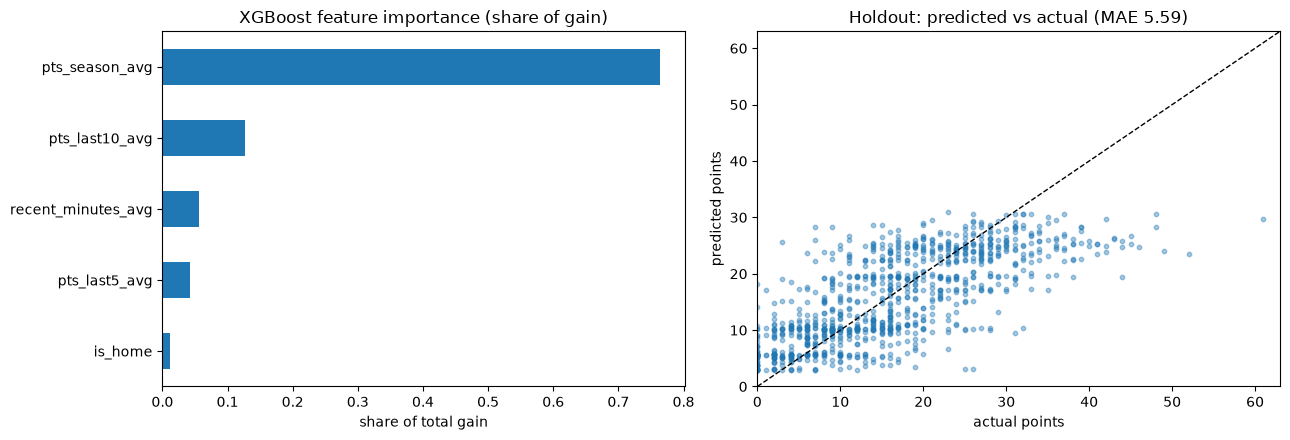

In [10]:
importance = pd.Series(model.get_booster().get_score(importance_type='gain')).reindex(FEATURES).fillna(0)
importance = importance / importance.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
importance.sort_values().plot.barh(ax=axes[0], color='tab:blue')
axes[0].set_title('XGBoost feature importance (share of gain)')
axes[0].set_xlabel('share of total gain')

lim = [0, max(y_test.max(), xgb_pred.max()) + 2]
axes[1].scatter(y_test, xgb_pred, s=10, alpha=0.4)
axes[1].plot(lim, lim, 'k--', linewidth=1)
axes[1].set(xlim=lim, ylim=lim, xlabel='actual points', ylabel='predicted points',
            title=f"Holdout: predicted vs actual (MAE {metrics['test']['MAE']:.2f})")
plt.tight_layout()
plt.show()

In [11]:
residuals = test.assign(predicted=xgb_pred, error=xgb_pred - y_test, abs_error=(xgb_pred - y_test).abs())
by_player = (residuals.groupby('player_name')
             .agg(games=('error', 'size'), MAE=('abs_error', 'mean'), bias=('error', 'mean'),
                  avg_points=(TARGET, 'mean'))
             .query('games >= 5')
             .sort_values('MAE', ascending=False)
             .round(2))
print('Players with the largest holdout error (bias > 0 means over-predicted):')
by_player.head(10)

Players with the largest holdout error (bias > 0 means over-predicted):


,games,MAE,bias,avg_points
player_name,,,,
Nikola Jokić,10,9.86,-7.12,33.30
Jaylen Brown,8,9.34,6.37,16.38
Devin Booker,15,8.90,-0.41,24.80
Anthony Edwards,15,8.72,-2.99,29.00
Stephen Curry,56,8.57,-0.64,26.14
Bradley Beal,7,8.32,4.77,12.71
Deni Avdija,11,8.14,-6.09,26.09
Kevin Durant,9,7.98,0.08,25.22
Desmond Bane,15,7.71,-1.54,21.20


## Save the model (optional)

When `SAVE_MODEL = True`, this uses `ml.model_integrity.save_model`, the same as `train_tree_points.py`. It writes the artifact, its manifest (with the config and metrics above) and a `candidate` entry in `ml/models/registry.json`. It is off by default.

In [12]:
if SAVE_MODEL:
    from ml.model_integrity import save_model, sha256_file

    training_config = {
        'training_script': 'ml/training/XGBoost.ipynb',
        'evaluation_module': 'ml/training/evaluation.py',
        'estimator': 'XGBRegressor(objective=reg:squarederror, tree_method=hist)',
        'xgboost_params': {**final_params, 'random_state': RANDOM_STATE},
        'tuning': {'param_grid': PARAM_GRID, 'cv_splits': len(FOLDS), 'early_stopping_rounds': EARLY_STOPPING_ROUNDS},
        'features': FEATURES,
        'target': TARGET,
        'train_fraction': TRAIN_FRACTION,
        'min_test_players': MIN_TEST_PLAYERS,
        'dataset': str(DATA_PATH.relative_to(REPO_ROOT)) if DATA_PATH.is_relative_to(REPO_ROOT) else str(DATA_PATH),
        'dataset_sha256': sha256_file(DATA_PATH),
        'holdout': holdout.summary(),
        'xgboost_version': xgboost.__version__,
    }
    entry = save_model(model, model_name=MODEL_NAME, features=X_train, dataset_path=DATA_PATH,
                       training_config=training_config, evaluation_metrics=metrics)
    print(json.dumps({'saved': entry['model_version'], 'artifact': entry['artifact_path']}, indent=2))
else:
    print('SAVE_MODEL is False; nothing written.')

SAVE_MODEL is False; nothing written.
